# Question 8 — Student Grade Prediction

In [1]:
from pathlib import Path
from io import BytesIO
import base64
import gzip
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', 40)
pd.set_option('display.precision', 6)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})

print('Python:', platform.python_version())
print('pandas:', pd.__version__, '| NumPy:', np.__version__,
      '| scikit-learn:', sklearn.__version__)

Python: 3.12.14
pandas: 2.2.3 | NumPy: 2.3.5 | scikit-learn: 1.8.0


## (a)(i) Load and inspect the dataset

If `student-mat.csv` is in the notebook folder, it is used. Otherwise, the embedded copy is read. The original file is separated by semicolons.

In [2]:
# Compressed CSV fallback keeps this notebook runnable without network access.
_EMBEDDED_CSV = 'H4sIAAAAAAACA71d224cR5J9n8/gF1TeqqrRTwR25ZclMOB6sI8Ljty2uJBFg6SM9X79dlXlJTIzMjIimxoIbhO0RaXyEpcTJ068ff7y8vL1/Hb53/PTb5fz0y+/vF7e3s6/Pv3+9vx/l/Pf396f3r+/nR8uv3w/f9o+Hv7n5Z/nT9vH6+Xp7eXb+bfvT6+/PD99O7+/Pv15+fr+/Pvl/Pb+/Ze/9q9+fXr++v36I89v+x/09v2P/Wdf//XH0/Mv56fP789/Pr8/X/+Hb99f3y6vf52/PP/25fJ6fv72fnn9dnk/v778/vTt/fnz9vteL1/Pv75eLvuP/u3l5fv7+d+evn4+/9f28eXy9PX9y/npn2+Xb5+vP/Andf5Jn38yf7v76e9357tPd2e1nu/+cf3yp5/N9fP+7myvv+6e3v/7y8vvl+t33i9Pn69/9vWrzy/baq5f/P7yvn9HX39N57u/Lm/Xb357yT6Obxb/yZ7N9R91/WXO8/nOXb89351nsJgFLubnu/3/BYvxf3Bayq9Px3fUsRTwR3fW465LMH4p9liKy5fijqX8x7/TSwn/DpuyrcRki6i+LNeybYvef9t1Rde/xXL9/nr9SVO9mrgx9vr/3x2ne/3G9ZL8+fx5/4F+eWk5ptgYxuexnO0v7LY/Rm27o+y2CrCiuVjRtvpqV/xq2sfU2Jzsyuj997ntnOZtJRPYm4e0knhS2++BWxIW83r54/v16T6/fCvOS7JBx+WxcVHbgR0b5MAGYcva9rS1QdhqiBsM746NT2pbib47PpRqvarwxMMK0gMv1pI97/JRNQ5L+cWo7X3P+aN6KB/V/XHTsKMitoW8N3Bjwh1W+8bsN2d7Vad6OeAOW9ER8S+M80tx+2JseV/wJ26z0wmPXXSNiR0y3gT6c96e1WZ2TsSStg3tvqzw2E1lesg9O/YpHNr+l9+XtN9m3bpDYZ8wU4h4CSU+Out3yXhbaIMttMQ92i1QOrrKbRVPTHJqbv/hh5fRYYsm8OCr9dzTpqfpKCjTs3/afUuS7dm3Zt4sH+Em8tNqvjElWAy0g9vf1GLH1FwLuDDgy8YjM+L7Y/aTOhZ2/fOV4SwM9aXokkzDSOOLiaEPeGQr5lKXakG6tVPVpT4uhPDdu/0ubTdKJc/hek6+dY+wB884teO8VHzvrd1hPveuoWZ7eAUcmSmDsYeW74i7U21TzyB27I8GrkxzQp89WmXYQ3xzaPPs/IUDoaoDNogdiaGnpfG8ohccWn+X43kZ4MO8Y33MHWtuieKJIVtkygfPc2IwoN+cxunuvBImSLdfPGKsNRUWVt9V3s1vh6Z8VA+W84BGHpzgWY1GidpvTBU+P0hyrzoXRM0PsZ7DfWkfSfvrPFOv695HrewgmrEzWJq8W0Ol7o6PbH9mOnBtJhjSSNoHHda7i8NVpBhRse0hdZeJgKwBJNjdw/vnfgobpHurEcQdA1bI+mMLZnoJF2nJ1/VI+LEEdpCGmrGiIlwsljQTwT0aCYn8RhP+0d5yTcDLa+Jam1tNUPP+mNKf2k5qqLFdKZ27xoNoIjI0eZq67cpC5O/1jZHgUCxHanycqqEtXPNDemRAG41nZcSXWIPjWjADjXl386/17igGVEccGoMzGzGr4q4qA+6Uf2FrSMi2MMjUQYcIIjscduPU8ANMSMd1o9wBsLZy5hxWqGPWMmtWfNx5/3T+uDZruMLDkjgMBJTvIOEciCPcn1OAyroBWScjLNKMvkHMHz/IelYPiSvu5UF8V7KL+wVighxgh/QB+FqAupxaBYN7bxu5rov/4v0tSgj9Grdnbu3OfeFIJQFQ76S0dxv7g9chRtTdGNHgAVnDAFlxXqijg7fhTl8/9NQL7JtPXgy1ZrYwXJ8sSbU9+Bd983UWDy503ySWZQN9GMTrP0vvdTERIDMC1xsPldnkw0p34TBYoQI3sIrc0GqSRVTlah7Q9645mMtxK7sAEIDr3B6ubg5jhinYJLg8Pbxuavrydu3A+qcP42dF2ENDBa3jKfOxN8d1jvlgI9AAgLjirEVL0ENvmEOJWwfDfKLO6r4uV/aNoR6qYsBqmMVQuw8uQPWzjeTDbGdNoAqPOnm8ziyCOooo+oR4+BnzFwjwwk2XO8CUKUvwSG3lsY1y1A5j/Ky0BzW3yx0fmcIDspy8wQwRbSNEpJbnwK85FTDJIDG7P62Xhl4jbtyREh9QPqBvkUGfGZ5By1JDE8FoC4HfE+lUeeZocJMiiGc91DnBIuZEHF0ba2AEIGy04UCDPV+AtJAl2iAJYpk3XO1OM/j/Ri2hxqkU1ypZseO3MZXejfaSQ0QAaMgDR3akr1vpELmmULLbL/laFzfKNRnM/aO3W+OH1o7ZrE89TEiHZgzmRM9scEFMflmCGA3P+WtW9mpl1UwDeHfNl19iVaq7O9Cz6RbS0AaHQr3O354ZLT0LDqsZzfJq87quR7HZAt3UXo4tBrjK2VZ2zyyIfwCTKuWJu88/FfE1vpiJScaRggwGOPu1lZrNnEomD/XouzLnw0bPvcLrdQvG6uqirirRWim8oy7Ne4xhRVitM8a/I+i+t6BUiTa1mWVXM0zIIosQ3uxbZhNr4IDH1cOBNcGxRePE7g7BYpiGRV4ym/+5zdz8KHZiQqhcJEXPdDGKT1nQssweVsKNpyY6DoVTES+LBdg3QozAF7cwUx0FhBphho6kDqbtsTFH3E3z0uSY5Af2gc+9ajTwbMAVjVL74Q6TBMhmURjP6jAYh7RHwOlEhToHFbuG2kYeF4TtSWr9/cdAQjR/PCQ8ao2x2DLYddCjbdKXOT33KeY5K3mDRF0HYmKi9SzycIn2vGIBVTrshRm+ARLw/E0MwnRIAme0+tSqrPAsM59db2IYNrVucs9Z9K6yHamqWo8DzbCGYHuZTm0Rq02yZcGHR2zVsSSfauBTi00hvdNaBuHl2aBNdRbXaTRCw1WGz+hGrTYSYBzAEciA1WINI+JUsBmVWX9m8f70Ge2GrIF3wcROocWl1H2pSZsCfn2j7iNNTgP8a/eyvLfSTrAkqqpqBihuibI0QRu9CMgdxJVWwkixpG9ODRtEcv0JHs4Ieui8BdIzFdRHiNXwd2eskc9iTWIrUa/LQg7cbaQ7ZOUdsuECqalVaGGRoz8E7nXRaZgN4fCdqSsJjhnq9gy+rvIya+ywcEqr7QZAtgGpkp8He/24zr2yc6NVraII3NS06yLgYvNy6kxyFhpUbdL48NCxo2yRAqDVU3DUiShhGk7EAS+REpd5FWT+LkTlqceVROBMIa8sxWQOv0QPLdYLq5lGSbH51M+3G5/qxB5QIqkSMbkkHT7xYgOu2ykvYYoaED6CLelipyHRceSoOLFBS4a5vKw6n8IOndOVbM9Qt6sGGIuc++5tXW6yxaVeqsSHIkumlmKC+9tuKT66aa5f+QaNhe41Mt2gvtlf2H9iAYY+bKIlaG5gbzLzQ3O5mt2FjQRMC6veLJy1iH/EvfLhfc1hSQ3xCZDNWyQmQ6m/Ax1HeY+YwYw0r81ZFtJTlI7jQqvIrFcU4W1UfIJTb0oofeoY6T4u5uVRrOC5bCM2+0lRrZd19xxvZ0QcF5dT7hasqHIqNmfqyN3kGjNtUkL+YYBB1jGIhw50xZpDJFimlt5hE82g35vrLaaRqOFAlQONHe3n221eQ9yDpIFkUw8RZXitBpm2go5EgNAWNqUtahabGNUUI4IRMjTcn9daL2bhdPIwBDm6GxPM3555aRgza4Lv20URbvDoQUvB96NqrOSOXh6WyJaVFFGi4QEdhaf+zSkRqD5wKETFsgXt4emUP/eF3h/iLrPUFAC/xkahiQCvFJszU3BPyyJryga23xQIk229KTOmQMaFwrgtBqB0qwKd/wgpNO44B0yyPIcoKWsz1gffYR1RlA1dY2F9BomGajce/p56MhOimrvYkerYWaSR3JhxanQyYQb4Wbpi0asuJztzXKT1Gci3kvMCskDmRj5UQ+Sm09HofBoxHQQkjkPnEZCG6DU6rWblwMymozkIlyPbGxOf+37j5iONmPg58VgZkGDX5Fop45IX3IyPePQmcsXcORGhJgLV1VxHYcEtZooRhUg5XpuSfrlir5tRnOispFyU9nClOyy5V4yizbFiXhmsQY8qm1hvZUIjiuaU+g2zz+KllUMwoQvlncSKsa0fkCS0rP9VXVZ8G1iu1sa+btuwgQsPOOU0MfaDHh0bdTKurCbRbiPE4pievCA9qgjkFvW2pWhlUALimhLFyjr2MRxKBXMICgv14MfRJNQwAmYQue/N9/sF8sTvtcNe4dILTXtjsJUkPPBg7i6EAloXbUd9uRKT1ZxH4lxbNnOp+nJ4JwWjUh6/0IAmhqbDeuxK66BqmZoftGeZjU2S06fEKHzodQiSu6IknR02l4Vb0Bz4H1VJhDY1bNSi+DJABNYXjKaGBuRj05FThs+C+K9jYxJicbztGBqv6CEN6VHCoyJY8eCkXKwQ54iO7tF1GYCXFh2U9VGOhYK4U5eUxo/TJynHW2ftWxXJ4CNqD1zhLBX5DnjOMPNEMT+iYyHamkoP13bLsJZV+JTgSyHzdanFth0fA3szDatismLRlONp2IU41zawJ8L0gboIOfBlOB1cbcOMXGrD5XwWFFQD6mkTyfA2P+jUwv64UpBb5cWjhe7TZolfsznw8Bfazj7URsFaUvOZRXoBLDkqUk3ZsAkGQmHDwDr3O4RI8NeVtRY1n9JmkWH/nvaAqMw/oDmfGSJ4c2qyOhJlbEs8ff6XNbMabxTD4I/TzfTKW6RrbOSCmFyCSRP5uRb2lcmlR1xsqHc4pxorP/Kt4tg1MpE541IX8kr2KenhBXX3ScWMVB3ydNXRNa0Ql52vh15+kIxRTW3lGcN1RS0D0tE2JrvklFhdnirLRWhFb+643GhX6YJVJCtukbgFj9bKNEfC7COQE0nd47JjJehT6Jf00iecZhzdvtASolxPEk4fjkxhcFhnfpV8RTxCvAEamScSUmgxCYvbLQ+EQlDmPC8DbxUYQsBvIMvZKCroMDm2h9Yt6nQMaGkdsjgqfArIgpEa2RKrYl51WWNH9dcWdv8UoYTN3CINlYUSrIoEr7mfb8ZmMHuWx2bGZ2MGVNZVt1bB2ZsGItWRg7PeaWnboqjNdPbckcMeqiK7CIVP+CbRwq/sYJr10p0v2qKyS5+4b53aHKEEto095DMySqbpMG5rbsVrFjbKZNnmbX4c1amRTmtKiiNmLyHhHeSPTNJ5I5WnqOfNbklXduNM1Cy9mqlGK+CrAUTRBChvZQAe9yL5t5KmwRhPEmo724oI2eBe8vwRUqsKEKzbEdnMY8kiFnpsUKXFhamwFyYZG6VHWgITIG2DIktxXCcxMvUy3tlhQe6lUsC69vDfD58PCYpO9mhSNDA/pYWD9a0eoyurnCgJGmvkWpkIJ96eOACP+7lsLhZZ1vpSd0+Mm71T3N1QlTsUayh/mstUieFx7tze5FR1a6onC9yktAwl5blU9Ln+Zn2c1/UfS9CzyiSslJ8d5CUEanwQn91emF/NSsKJhrDO7ck2vbtjYsF7//su6D2men5FlHi+KfR1lVPjKteNtmik8XFDo3SkqKbbMzCfuymcpdjQL8AQY4paFDE5GFBXBFvQXqajypDJU4ylZ50ZI22Ghve6QH/E5yXMbO63ZFpTZ6BW0XpnCbKYEem6KmnbOJDSSIyxhYzl9Y8aNhakzdTU6rKt0R9zY2WFo/togAQlynNZB1m0dmiuTZqNZNKgnWIo9cKZ5YBUm40UIDOgIKbiI5vwilhnMK24ustZk8Ue2gM3l7+5OzonS6n2gMiFy5bnBtK8YYMupIhhYRzZCPnJSVpjwmxPjfX+N3u+foT7SC3Bao2qCHOPcsd09QOPLRkjUF854WOpWfPiOiw3moVjfY8DkNIx3Q57JRoPydscODRTR8eqaxvEDBWZHZTkKBCVRUEGe/FkFMTxZErEZnWRKJm0OqceRamvzqDl9ll7u2PDpDjd5WLfN2lu5IJEgWIarDURZFYxhWtA1NBCftvcbHq9ZZKVsIQK2uDw17WKBCg7gB2xLjiUDaeIj0lhGmkpDmanM1Zsemil7owYY6AsCAf5VSjddS0b1EGOQOmwSExHQKOWWTse+XYecw1irliRkkOcV7i8EU+neC9wm1rWfq40RvRtY9hITXJLzRhZmUqTzG4LijaftfnPTF5dJ7rJPSZzxkieaOmAw1fdFqiR4V9hxbvCAZZzMb7ZN+dEEzW4GRbLGWSYnE6zKtZ6HcvQOhSrnaue2GNBK7TGuXN5WM4JIJRUr8zm8nKIiv5C6wHKx1DxUhfoECxihEMtKZ9/i/aR3qQWj824V0DCvh+KKrkSFltmTnsJIccj+EhmKFtxhdSAZtIpVY8nIraxXPlWecEt6MztjkIFhk8ZVqy8AvKHNvrD+TQrIYvFxQeNyA46sA5FZHg3zT3gGWQNixIY2WClqyQSRJmJBgLWXKiSTK1Y656j3XhbO4xOE15NuMKlwPfCHMj3MfNmra+SRL2Vknaw0lJq4w0x1NwDHS2hxnosVrJl8UOht0wc2fhpQuFukxul2eUJ3fVdtRKC8aU2LBHuUjPqh4YUjSXFSOfrSVuV/8R590aC59iRt58AXNtyqOtHo6Ut7pwBgFcL4qZI8YSGhubR1NKXxufEQbOVCjXyPh2wCrL5VQ81v6YhLLrVqdwLgHrAF5tMgw2kqqG46tHfFz5eMEGsk2nYGKm68+Jq54obRcsdmjMgeamjLoLWrDfPaZ8uIFxZzUZH/MtGO1RHZKMzgfXIyKWkjrxC7LSJLd8fJ80an6EGuoVcpGMZBoEuXGdeyV9xNAPLRNV3dp6Qgs0nBAqT8EU0221kFDEYSmsOnCtwGhJtfwduc6OBaRmc46FlI4mh8hyI68kSrWIPJKZUJJp5VxCT1ViAyEg06is0OOwtX9C2QwDuPvWYTyjRiDk1kL0sdXTi1XmhEDbsrktgFW1CM+v4ozLU9x/VisIZ4L793lNYlukg0I1ZGjf2dmftVfvbU5gwcJMeKpimMXCrNGzZwTtOUdKPDMpTojJ3OjxXNAsbgmvcSqxF7oRuQdXgAa4NvOpxeC6uHqCOOkDqXyE5wfZ6vftdV2pERjSUnywEhimVewbP5gaMRse+8x7omUeRjQjgppQo+F2daV+sPfyV6XftLR5lal2dldtEeNvt8S08NqayDhIj59Zp3beuD6+DsKdtFdMP20Ku0A6VWqCy1zDMOCsVQ5KpNVt+GZ5irG+LR6Ln0B3cIdcMZk3Lk7Xs6Yy/sZRDcR+4TU41jKYGhj8G+oaeYGBkyMDWclzrjU08Js3wq8XdNwbFVHURdpAZIeUGpGguGwaAFoFObCQE9xpqoNMydV6ZFa1GnzD5gts4bXTvg6ulQcpc9kRLqdMdfBRE06yUB8K4yrD9iVxTb1wUg+SPfhkYtXn7OQWiN9jrxb+NGM6HlVY9dSrkOUhMEYP68XTjnAJCvIcTNUUTOyZW4PpSj5tnk9uSRpGOvNHeQKTiPpfNaSAN0sz9iWhsxIksTBZNvphHmVoA0unEpfmmBdmpdWS9ZF/MG+Woy/jQxWONkzR2vbldrmoEO6VK8IngQLcb8xFuhZEGHqHK6ajwrAPo3z67vEZjjdchVF2wAWHocOWJ+C3WYHKewUbn/RgUtK33Hh+9rltCPqEi2VqwQ2ZIZSbprHOOjWa3Mq52dyJk0ExyCUK3eFNz3KapU+2Eg9CE81sCe12fm51zKzUzYIimQyVA8bBOmHTcwqzaCxT6O1bI+T5Q05r5vDCH+6HTQaSMvECOPrApxZG8+cETiVzs0rfnBWc1LTdMthpg+afyh22pRK+icXptaifjTrvIlNZVyRXvLaJHs3EsDyl344vk0PZYwqkSKnIfwOrM9DiWmqWzCjrSRvqHC26FbodiQ6MvdMkq5Y0xSAolCLq6dCa+Ci1y19x4VteMuYcqjEcEkipv1Yri+wIlNmbsSrf6BllN5x+gb2Ojr4pdcSt9dyUvyQ4ofgV60AJPammZmvsfsjXQj3tq2YkAMTh1VdatYWU3h/xPQ5RWzA5qK7cIIp1UQ0GYt8XtsUPK1Pz5oSZUUmeOSq5mxqQDTVcGiIgn2e6px5dkzR4zA00QQRDAtkKulbI5ZGeREfYru5g+HO/cNEpMj8LBnbesKLR42p0XMGMx8njXgRnIiq0XO3XZ4zqxaQFdmZ0hpbggVVm27z38503tEJTYKbpv2qcQLnC1FXCjcTEnbPBYlx5t0IkcnamdwRqucMB9XAiv1P4RrdyB/mdg5325LzUlWjCwjt9lCQzzsaAF3RzylPDw2AyI4ybsy0JWJDyjR0GXEw82bcXqOW8dArn7eoQ5DGPYK2cgOFDRAhlwXNBC94ggW3WbaIzJpJ51eZE/tZisw4NcenukgPp0OayAeFukzWH0vLc1+DXw6ZBLX96hVumPnn5t5PLlGmR9KxBXhgvKWrHUD5jhnoXLttQaM7Wz6lVGy4hH92qQ5ay4hJbqgqM58tqx5UxyRQDQVp1VJvDHFd47U+1wgAupQYG0hHGbNqhbHcVMEGN+pykYkFD2rBnrKGYAz3brWRu89aVa9LEzSFnkDTIjQ/7A/M76feGnpfhAtxlgaIChjPlU0eY70/wBmnqAvJYGFoD5wYiVfmTMMy69qhF1M0dlOB0kPKeCixnX06v6NyNnXarRdqMiA+ptNsoynUgb3RtPIpnoQEWrpuBBlYYRL0YSXXyGD6NGwggkZaFhImkRh0SZWlW2ELMe86PmqCKDO/dWjU2gBddNuZKzOIF2jOa74jTxWDm+nKCDpBAA33fOm2s2MmPiUFr2vB24MFk/bPeUuMCKuNPbxekEuuhwokMfqfgGx2MpyFXJmhqar8mItIu1nCHikm7K0nHs/dLjTaqGecdn3VDdDHvQFvg6xFDiglZqG3DRly8EqqLp7nc6FOSyYzUWLkvAJmxnlGDoWYrdC73r5gFZhgJmtQpeIctn6aQ/6BUcR6PRTBwlAJM6122gY6z0cjrNSmZkjKCN5bW9Up3GrMJA65ESJichZSXVVAQc+CW/NHihT424BUF5DfjvpGDV9AqKqS8moFAfYzFTzz36moL3jpAFh+7VEdqgrrLzFWu7l7FOOQz3gE6vUKIx9xLZsyCzffgoHw5DTGfbIMUJs7CeAMPPx51/5CEun6JQezNRYAsHmgEtOOXldLKRQoU3aMOACHSSfLaSst80EPoPAdbpb/8PzbKUS6HeAAA='
csv_path = Path('student-mat.csv')
if csv_path.is_file():
    raw = pd.read_csv(csv_path, sep=';')
    print('Loaded local student-mat.csv')
else:
    raw = pd.read_csv(BytesIO(gzip.decompress(base64.b64decode(_EMBEDDED_CSV))), sep=';')
    print('Loaded the embedded copy of student-mat.csv')

assert raw.shape == (395, 33), 'Use the original mathematics dataset: 395 rows and 33 columns.'
print('Raw data shape:', raw.shape)
display(raw.head())
raw.info()
print('Numeric summary:')
display(raw.describe())
print('Missing values by column:')
display(raw.isna().sum().rename('missing_values').to_frame())

Loaded the embedded copy of student-mat.csv
Raw data shape: (395, 33)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


,missing_values
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


## (a)(ii) Select and transform the variables

Encode `schoolsup` as no = 0 and yes = 1. Set `alc = (Dalc + Walc) / 2`, then remove `Dalc` and `Walc`.

In [3]:
selected = ['age', 'studytime', 'schoolsup', 'goout', 'Dalc',
            'Walc', 'health', 'absences', 'G3']
data = raw[selected].copy()
data['schoolsup'] = data['schoolsup'].map({'no': 0, 'yes': 1})
data['alc'] = (data['Dalc'] + data['Walc']) / 2
data = data.drop(columns=['Dalc', 'Walc'])

features = ['age', 'studytime', 'schoolsup', 'goout', 'health', 'absences', 'alc']
data = data[features + ['G3']]
X = data[features]
y = data['G3']
assert not data.isna().any().any()

print('Preprocessed shape:', data.shape)
display(data.head())
print('Preprocessed summary:')
display(data.describe())
print('Missing values after preprocessing:')
display(data.isna().sum().rename('missing_values').to_frame())

Preprocessed shape: (395, 8)
Preprocessed summary:
Missing values after preprocessing:


,age,studytime,schoolsup,goout,health,absences,alc,G3
0,18,2,1,4,3,6,1.000000,6
1,17,2,0,3,3,4,1.000000,6
2,15,2,1,2,3,10,2.500000,10
3,15,3,0,2,5,2,1.000000,15
4,16,2,0,2,5,4,1.500000,10


,age,studytime,schoolsup,goout,health,absences,alc,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.035443,0.129114,3.108861,3.554430,5.708861,1.886076,10.415190
std,1.276043,0.839240,0.335751,1.113278,1.390303,8.003096,0.992195,4.581443
min,15.000000,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000
25%,16.000000,1.000000,0.000000,2.000000,3.000000,0.000000,1.000000,8.000000
50%,17.000000,2.000000,0.000000,3.000000,4.000000,4.000000,1.500000,11.000000
75%,18.000000,2.000000,0.000000,4.000000,5.000000,8.000000,2.500000,14.000000
max,22.000000,4.000000,1.000000,5.000000,5.000000,75.000000,5.000000,20.000000


,missing_values
age,0
studytime,0
schoolsup,0
goout,0
health,0
absences,0
alc,0
G3,0


## (a)(iii) IQR outlier counts

For each predictor, $IQR=Q_3-Q_1$. A value is flagged if it is below $Q_1-1.5IQR$ or above $Q_3+1.5IQR$. G3 is not included in this calculation.

,Q1,Q3,IQR,Lower bound,Upper bound,Outlier count
age,16.000000,18.000000,2.000000,13.000000,21.000000,1
studytime,1.000000,2.000000,1.000000,-0.500000,3.500000,27
schoolsup,0.000000,0.000000,0.000000,0.000000,0.000000,51
goout,2.000000,4.000000,2.000000,-1.000000,7.000000,0
health,3.000000,5.000000,2.000000,0.000000,8.000000,0
absences,0.000000,8.000000,8.000000,-12.000000,20.000000,15
alc,1.000000,2.500000,1.500000,-1.250000,4.750000,9


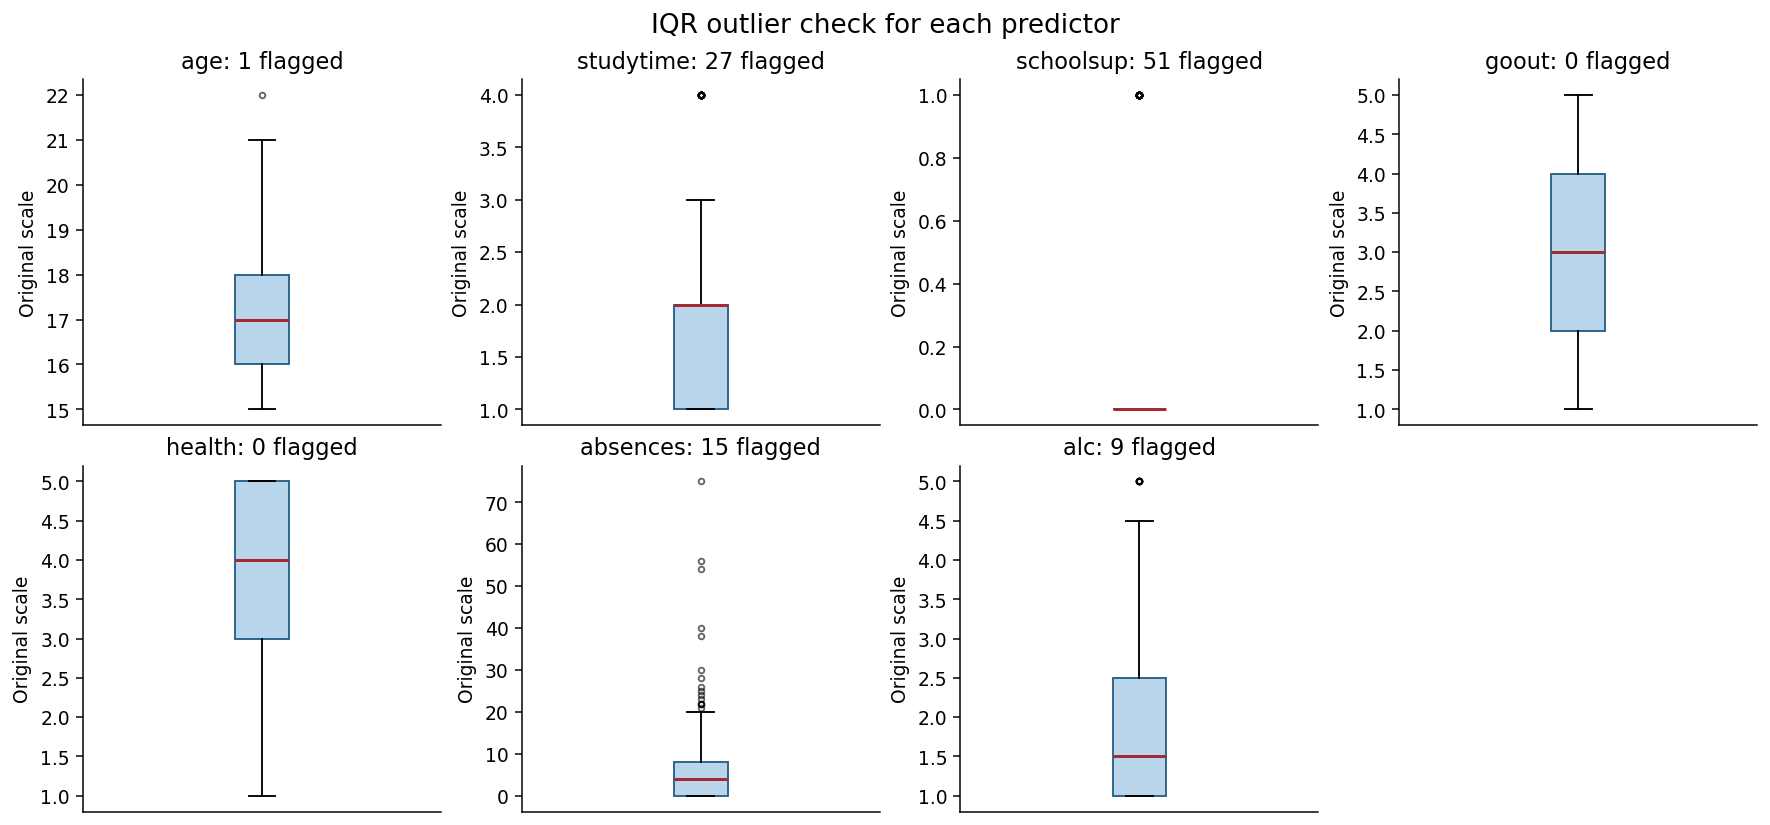

In [4]:
q1 = X.quantile(0.25)
q3 = X.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outlier_mask = X.lt(lower) | X.gt(upper)
outlier_table = pd.DataFrame({'Q1': q1, 'Q3': q3, 'IQR': iqr,
                              'Lower bound': lower, 'Upper bound': upper,
                              'Outlier count': outlier_mask.sum()})
display(outlier_table)

fig, axes = plt.subplots(2, 4, figsize=(13, 6), constrained_layout=True)
for ax, feature in zip(axes.flat, features):
    ax.boxplot(X[feature], patch_artist=True,
               boxprops={'facecolor': '#b9d5ec', 'edgecolor': '#286087'},
               medianprops={'color': '#a52b32', 'linewidth': 1.6},
               flierprops={'marker': 'o', 'markersize': 3, 'alpha': 0.6})
    ax.set_title(f'{feature}: {int(outlier_mask[feature].sum())} flagged')
    ax.set_xticks([])
    ax.set_ylabel('Original scale')
axes.flat[-1].axis('off')
fig.suptitle('IQR outlier check for each predictor', fontsize=14)
plt.show()

The counts are **age: 1, studytime: 27, schoolsup: 51, goout: 0, health: 0, absences: 15, alc: 9**.

For `schoolsup`, both quartiles are zero. The IQR rule therefore flags every value of 1. These are valid binary values, not necessarily data errors. Ordinal values can also be flagged despite being valid. The question asks for counts, so no rows are removed.

## (a)(iv) Standardization and PCA

PCA is fitted to the seven standardized predictors. G3 is used only to color the points. The table reports component weights (`pca.components_.T`), often called loadings. Larger absolute weights indicate larger contributions to a component. Squared weights sum to one within each component. Component signs can be reversed without changing the result.

Explained variance ratio:
Total variance represented by PC1 and PC2: 40.81%
PC1 strongest features: alc, goout, age
PC2 strongest features: age, schoolsup, health


,PC1,PC2,PC1 contribution (%),PC2 contribution (%)
Feature,,,,
age,0.381940,0.589260,14.587797,34.722778
studytime,-0.329734,0.385671,10.872429,14.874193
schoolsup,-0.248184,-0.464202,6.159517,21.548334
goout,0.493755,-0.139613,24.379403,1.949191
health,0.080545,-0.400925,0.648752,16.074067
absences,0.280106,0.182798,7.845934,3.341518
alc,0.595871,-0.273677,35.506168,7.489919


,explained_variance_ratio
PC1,0.236757
PC2,0.171366


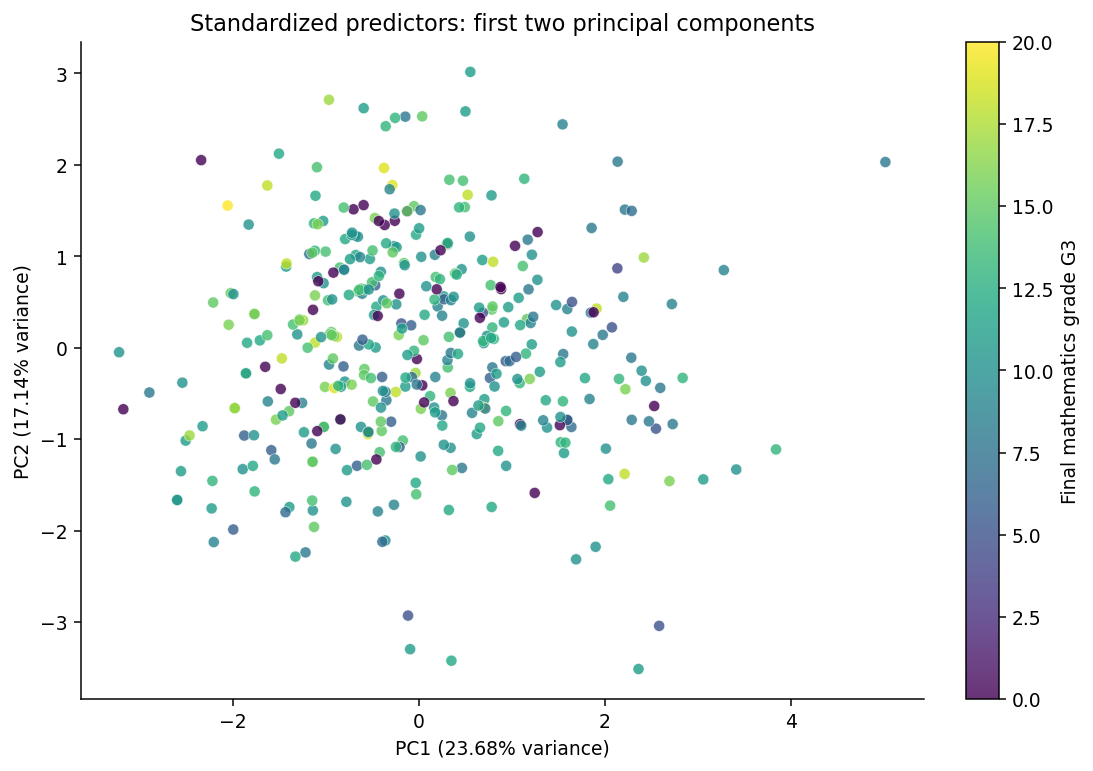

In [5]:
# Full-data scaling here is for exploratory PCA only.
pca_scaler = StandardScaler()
X_pca_scaled = pca_scaler.fit_transform(X)
pca = PCA(n_components=2, svd_solver='full')
scores = pca.fit_transform(X_pca_scaled)

loadings = pd.DataFrame(pca.components_.T, index=features, columns=['PC1', 'PC2'])
loadings.index.name = 'Feature'
contributions = loadings.pow(2).mul(100).rename(columns={'PC1': 'PC1 contribution (%)',
                                                       'PC2': 'PC2 contribution (%)'})
display(loadings.join(contributions))
print('Explained variance ratio:')
display(pd.Series(pca.explained_variance_ratio_, index=['PC1', 'PC2'],
                  name='explained_variance_ratio').to_frame())
print(f'Total variance represented by PC1 and PC2: {pca.explained_variance_ratio_.sum():.2%}')
for component in ['PC1', 'PC2']:
    strongest = loadings[component].abs().nlargest(3).index.tolist()
    print(component + ' strongest features: ' + ', '.join(strongest))

fig, ax = plt.subplots(figsize=(8, 5.6), constrained_layout=True)
points = ax.scatter(scores[:, 0], scores[:, 1], c=y, cmap='viridis',
                    vmin=0, vmax=20, s=35, alpha=0.8, edgecolors='white', linewidths=0.3)
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%} variance)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%} variance)')
ax.set_title('Standardized predictors: first two principal components')
fig.colorbar(points, ax=ax, label='Final mathematics grade G3')
plt.show()

**Answer:** PC1 is driven most by **alc (0.596)**, followed by **goout (0.494)** and **age (0.382)**. PC2 is driven most by **age (0.589)**, followed by **schoolsup (-0.464)** and **health (-0.401)**. PC1 and PC2 explain about **23.68%** and **17.14%** of predictor variance, or **40.81% combined**. These components summarize variation in X; they are not chosen to maximize prediction of G3.

## (b)(i) Split and standardize for model evaluation

Use an 80:20 split with `random_state=552`. Fit a fresh scaler only on the training set and apply it to both sets. This avoids leaking test-set information. The exploratory PCA above is not used to fit the regressions.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=552
)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train),
                              columns=features, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test),
                             columns=features, index=X_test.index)

assert len(X_train) == 316 and len(X_test) == 79
assert set(X_train.index).isdisjoint(X_test.index)
assert np.allclose(scaler.mean_, X_train.mean())
assert np.allclose(X_train_scaled.mean(), 0, atol=1e-12)

print('Training rows:', len(X_train), '| Test rows:', len(X_test))
display(X_train_scaled.head())

Training rows: 316 | Test rows: 79


,age,studytime,schoolsup,goout,health,absences,alc
125,-1.323751,-1.290019,2.422719,1.724515,1.024259,-0.689096,0.668590
99,-0.543331,1.073147,2.422719,1.724515,-0.401582,-0.689096,-0.877321
163,0.237090,-1.290019,-0.412759,-0.113417,-1.114502,-0.445250,0.668590
128,1.017510,-1.290019,-0.412759,-0.113417,0.311339,-0.689096,-0.362017
55,-0.543331,-0.108436,-0.412759,0.805549,-1.114502,0.286287,-0.877321


## (b)(ii) Fit the three models

Ridge and Lasso both use `alpha=0.1`. All models fit an intercept.

In [7]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=0.1),
    'Lasso': Lasso(alpha=0.1, max_iter=100000, tol=1e-8)
}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    print(name, 'fitted')

Linear Regression fitted
Ridge fitted
Lasso fitted


## (b)(iii) Test metrics and best model

Lower MAE and RMSE are better. Higher R² is better. MAE and RMSE are measured in grade points.

In [8]:
predictions = {}
metric_rows = []
for name, model in models.items():
    prediction = model.predict(X_test_scaled)
    predictions[name] = prediction
    metric_rows.append({'Model': name,
                        'MAE': mean_absolute_error(y_test, prediction),
                        'RMSE': np.sqrt(mean_squared_error(y_test, prediction)),
                        'R2': r2_score(y_test, prediction)})

metrics = pd.DataFrame(metric_rows).set_index('Model')
display(metrics)
best_models = pd.DataFrame({'Metric': ['MAE', 'RMSE', 'R2'],
                            'Best model': [metrics['MAE'].idxmin(),
                                           metrics['RMSE'].idxmin(),
                                           metrics['R2'].idxmax()]})
display(best_models)

,MAE,RMSE,R2
Model,,,
Linear Regression,3.418009,4.755812,0.028177
Ridge,3.418064,4.755860,0.028157
Lasso,3.447338,4.794612,0.012255


,Metric,Best model
0,MAE,Linear Regression
1,RMSE,Linear Regression
2,R2,Linear Regression


## (b)(iv) Interpret R²

$R^2 = 1 - \frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y_{test})^2}$.

Linear Regression has R² **0.02818**, Ridge **0.02816**, and Lasso **0.01225**. Relative to predicting the test-set mean, these models reduce squared error by about **2.82%**, **2.82%**, and **1.23%**, respectively. Predictive performance is weak on this split. Linear Regression wins all three metrics, but its advantage over Ridge is extremely small. This single split does not establish that it is reliably better.

## (b)(v) Coefficients and intercepts

The feature coefficients below use standardized X and unscaled G3. A coefficient describes the predicted change in G3 for a one-training-standard-deviation increase in that predictor, holding the others constant. Since the training predictors are centered, the fitted intercept is the training mean of G3.

In [9]:
coefficient_table = pd.DataFrame(
    {name: model.coef_ for name, model in models.items()}, index=features
)
coefficient_table.index.name = 'Term'
coefficient_table.loc['Intercept'] = [model.intercept_ for model in models.values()]
display(coefficient_table)

,Linear Regression,Ridge,Lasso
Term,,,
age,-0.785327,-0.784976,-0.630919
studytime,0.449134,0.448974,0.351270
schoolsup,-0.717780,-0.717459,-0.570052
goout,-0.570108,-0.569917,-0.477690
health,-0.245802,-0.245702,-0.141941
absences,0.197840,0.197726,0.070763
alc,0.036301,0.036145,-0.000000
Intercept,10.613924,10.613924,10.613924


## (b)(vi) Relationships with G3

Holding the other predictors constant, the fitted models show:

| Predictor | Relationship with predicted G3 |
|---|---|
| age | Negative in all three models. |
| studytime | Positive in all three models. |
| schoolsup | Negative in all three models. |
| goout | Negative in all three models. |
| health | Negative in all three models. |
| absences | Positive in all three models, although the coefficient is small. |
| alc | Very small positive coefficient in Linear Regression and Ridge; zero in Lasso. |

These are conditional associations, not causal effects. For example, the negative `schoolsup` coefficient does not show that support lowers grades; students receiving support may already be struggling. Unexpected signs should not be treated as advice about behavior.

Because `schoolsup` is standardized, its coefficient is not directly the no-to-yes difference. Divide it by the training standard deviation of the original binary predictor to obtain that difference:

In [10]:
schoolsup_index = features.index('schoolsup')
support_effect = pd.Series(
    {name: model.coef_[schoolsup_index] / scaler.scale_[schoolsup_index]
     for name, model in models.items()},
    name='Predicted G3 difference: yes minus no'
)
display(support_effect.to_frame())

,Predicted G3 difference: yes minus no
Linear Regression,-2.035251
Ridge,-2.034340
Lasso,-1.616371


## (b)(vii) Compare regularization methods

Linear Regression minimizes squared error without a penalty. Ridge adds an L2 penalty and usually keeps all predictors. Lasso adds an L1 penalty and can set coefficients to zero.

At alpha = 0.1, Ridge is almost identical to Linear Regression. Lasso sets **alc** to zero and shrinks the other coefficients. Its test errors are slightly larger. In this run, regularization does not improve test performance. The selected predictors have limited predictive power for G3, and alc adds little linear information after accounting for the other variables. A zero coefficient does not prove that alcohol consumption is irrelevant in general.

The same numeric alpha does not imply the same effective penalty strength: scikit-learn uses different objective normalizations for Ridge and Lasso.

## (b)(viii) Increasing alpha

A larger alpha strengthens shrinkage. Ridge coefficients move toward zero; Lasso can set more coefficients exactly to zero. This can reduce overfitting, but too much shrinkage causes underfitting. Test MAE and RMSE may rise or fall, and test R² may rise or fall. The changes are not necessarily monotonic. Select alpha with cross-validation on the training set, not by repeatedly choosing the best test result.

## (b)(ix) Suggested feature engineering

- Try `log1p(absences)` and an indicator for any absence to handle skew and possible nonlinear effects.
- Add a few plausible interactions, such as `studytime * alc` or `studytime * absences`.
- Try nonlinear terms for age or studytime. Alternatively, one-hot encode ordinal ratings if equal spacing is too restrictive.

Evaluate each change using training-set cross-validation. Keep the required baseline models unchanged for comparison. G1 and G2 are not added here because the question specifies the predictor list.

## Residual analysis

Residuals are defined as **actual G3 minus predicted G3**. A useful fit should have residuals centered near zero without a strong pattern. The diagnostic plots below use the held-out test set.

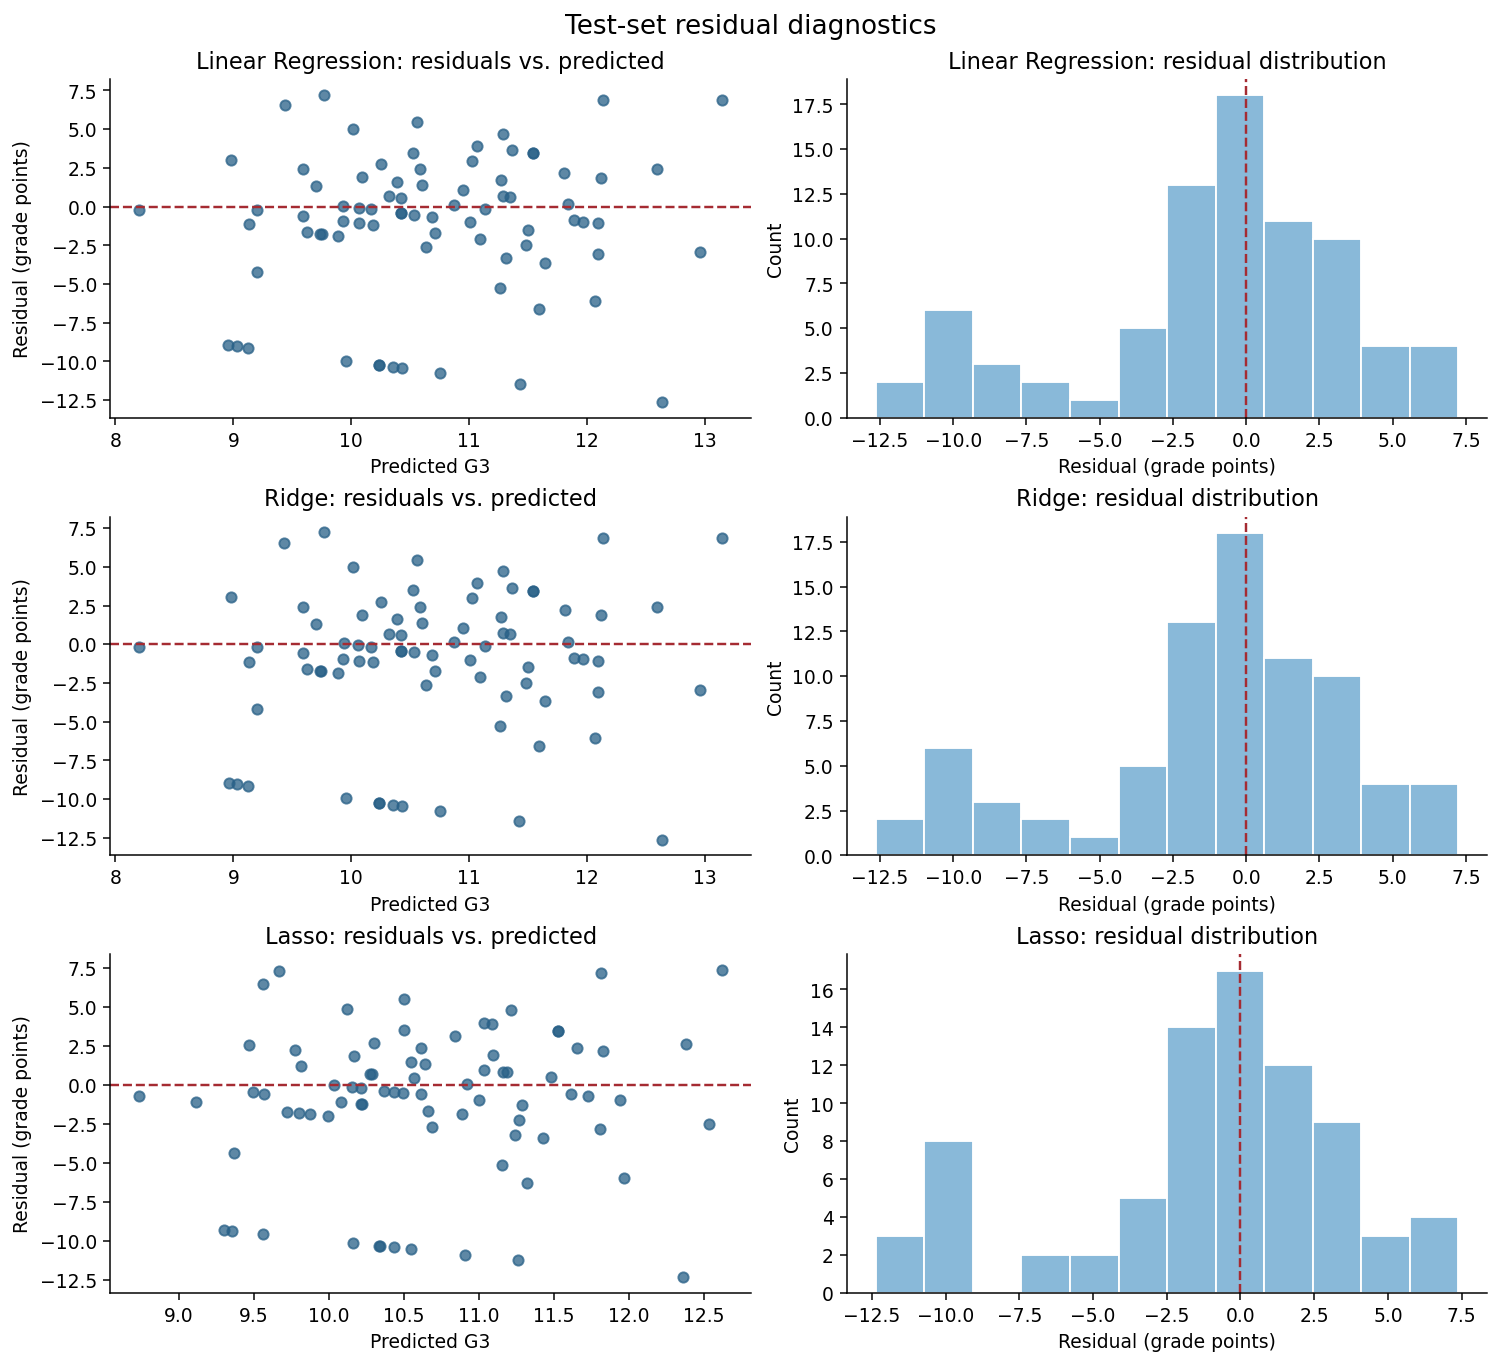

,Mean residual,Minimum residual,Maximum residual
Model,,,
Linear Regression,-1.070940,-12.637798,7.232635
Ridge,-1.070870,-12.636988,7.232613
Lasso,-1.048657,-12.360374,7.378865


In [11]:
fig, axes = plt.subplots(3, 2, figsize=(11, 10), constrained_layout=True)
residual_summary = []
for row, (name, prediction) in enumerate(predictions.items()):
    residual = y_test.to_numpy() - prediction
    axes[row, 0].scatter(prediction, residual, color='#286087', s=30, alpha=0.75)
    axes[row, 0].axhline(0, color='#a52b32', linestyle='--', linewidth=1.3)
    axes[row, 0].set_title(name + ': residuals vs. predicted')
    axes[row, 0].set_xlabel('Predicted G3')
    axes[row, 0].set_ylabel('Residual (grade points)')
    axes[row, 1].hist(residual, bins=12, color='#89b9d9', edgecolor='white')
    axes[row, 1].axvline(0, color='#a52b32', linestyle='--', linewidth=1.3)
    axes[row, 1].set_title(name + ': residual distribution')
    axes[row, 1].set_xlabel('Residual (grade points)')
    axes[row, 1].set_ylabel('Count')
    residual_summary.append({'Model': name, 'Mean residual': residual.mean(),
                              'Minimum residual': residual.min(),
                              'Maximum residual': residual.max()})
fig.suptitle('Test-set residual diagnostics', fontsize=14)
plt.show()
display(pd.DataFrame(residual_summary).set_index('Model'))

The residuals are spread widely, consistent with RMSE near 4.8 grade points and low R². Large negative residuals indicate substantial overprediction for some low-scoring students. All three models show similar limitations. More informative predictors or a better-suited model may help, but any change needs validation on data not used to fit it.